<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Multi_CPW_Hanger_Resonators_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# CPW Hanger Resonators

This chip holds two feedline passes separated by 4.4 mm, with both 300 × 300 µm wirebond pads at the left chip edge. Each hanger has an open coupled end, a grounded far end, and a 2 mm feedline-to-short distance.

The substrate relative permittivity $\varepsilon_r=11.45$ gives the initial quasi-static estimate $\varepsilon_{\mathrm{eff}}=(1+\varepsilon_r)/2=6.225$. The frequency list sets the total centerline length, including the coupled-line arm and all circular bends.

$$
\ell_r=\frac{c}{4f_r\sqrt{\varepsilon_{\mathrm{eff}}}}=\ell_{\mathrm{tee}}+\ell_{\mathrm{meander}},\qquad f_r\propto\ell_r^{-1}.
$$

Here $c=299{,}792{,}458$ m/s denotes the speed of light, $f_r$ denotes each target frequency, and $\ell_r$ denotes its complete open-to-short centerline.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip footprint | `CHIP_SIZE_X="9mm"`; `CHIP_SIZE_Y="7mm"` |
| Resonator population | First eight frequencies; counts stop at the final listed target |
| Frequency list (GHz) | 5.0000, 5.3636, 5.7273, 6.0909, 6.4545, 6.8182, 7.0000, 7.5455, 7.9091, 8.2727, 8.6364, 9.0000 |
| Feedline population | One by default; round-robin frequency assignment when increased |
| Feedline CPW | 11.7 µm center conductor; 5.1 µm slots |
| Hanger CPW | 10 µm center conductor; 6 µm slots |
| Coupled-line section | 500 µm length; 200 µm exit leg; 70 µm bend radius; open coupled end |
| Coupling metal-edge gap | 20 µm; `coupling_space="8.9um"` between the two etched CPW slots |
| Meanders | Native `RouteMeander`; 70 µm circular fillets; 350 µm spacing; 140 µm endpoint leads |
| Short termination | Native `ShortToGround`; 2 mm from its feedline pass |
| Horizontal placement | Up to four hangers per pass; lower passes stagger by 250 µm where space permits |
| Vertical placement | Feedline groups centered together; 4.4 mm pass spacing; 250 µm between groups |
| Wirebond pads | 300 × 300 µm; 300 µm taper; 25 µm lead; 80 µm ground clearance |
| Pad edge position | Outer metal edges 150 µm inside the die; complete launcher cuts 70 µm inside |
| Series feedline capacitors | Native two-terminal `CapNInterdigital`; five 20 µm fingers, 10 µm width, 6 µm gaps |
| Ground cheesing | Native default 25 × 25 µm holes, 100 µm pitch, 25 µm component keep-out buffer |
| Cheese boundary | Hole edges at least 100 µm inside the chip footprint |
| GDS layer | Layer 1: positive ground, CPW center conductors, and launcher electrodes |
| GDS precision | 1 nm |


## Quantum Metal documentation

[CoupledLineTee](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [CapNInterdigital](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CapNInterdigital.html) · [RouteMeander](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Native routing checks](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.24-Design-rule-checking.html) · [Native cheesing and GDS export](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)


In [9]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [10]:
"""This script builds coupled CPW hanger resonators in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "9mm"
CHIP_SIZE_Y = "7mm"
RESONATOR_COUNT = 8
FEEDLINE_COUNT = 1
FREQUENCIES_GHZ = (
    5.0000, 5.3636, 5.7273, 6.0909, 6.4545, 6.8182,
    7.0000, 7.5455, 7.9091, 8.2727, 8.6364, 9.0000,
)
CHEESE_KEEPOUT = "42um"
INLINE_CAPACITORS = True
OUTPUT_FILENAME = "Multi_CPW_Hanger_Resonators.gds"

# --- Imports and Design ---
import logging
import os
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
import warnings
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import DEFAULT_RULES, SHAPE_RULES, validate

plt.rcParams["figure.dpi"] = 250
qm.logger.setLevel(logging.WARNING)

warnings.filterwarnings("ignore")

assert RESONATOR_COUNT >= 1 and 1 <= FEEDLINE_COUNT <= RESONATOR_COUNT
frequencies = np.asarray(FREQUENCIES_GHZ[:RESONATOR_COUNT], dtype=float)
assert len(frequencies) >= FEEDLINE_COUNT and np.all(frequencies > 0)
design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
chip_x = float(design.parse_value(CHIP_SIZE_X))
chip_y = float(design.parse_value(CHIP_SIZE_Y))
phase_velocity = 299_792_458 / np.sqrt((1 + 11.45) / 2)
couplers, resonators, shorts, launchpads, end_caps = [], [], [], [], []
feedline_routes, length_records, placements = [], [], []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [11]:
# --- Feedline Groups ---
assignments = [list(range(i, len(frequencies), FEEDLINE_COUNT))
               for i in range(FEEDLINE_COUNT)]
per_pass = min(4, max(1, int((chip_x - 2.2) / 1.7 + 1e-9)))
pass_counts = [int(np.ceil(len(indices) / per_pass)) for indices in assignments]
group_heights = [2.230 if count == 1 else 4.4 * (count - 1) + 0.460
                 for count in pass_counts]
total_height = sum(group_heights) + 0.250 * (FEEDLINE_COUNT - 1)
assert chip_x >= 5.5, "Increase CHIP_SIZE_X for the launcher and coupler geometry."
assert total_height <= chip_y - 0.200, "Increase CHIP_SIZE_Y for this resonator population."
cursor_top = total_height / 2

for feed_index, (indices, pass_count, height) in enumerate(
        zip(assignments, pass_counts, group_heights)):
    row_y = [cursor_top - 0.230 - 4.4 * row for row in range(pass_count)]
    cursor_top -= height + 0.250
    rows = []

    # --- Native Coupled-Line Hangers and Meanders ---
    for row, y in enumerate(row_y):
        row_indices = indices[row * per_pass:(row + 1) * per_pass]
        x_positions = (np.linspace(-chip_x / 2 + 1.9, chip_x / 2 - 2.0,
                                  len(row_indices))
                       if len(row_indices) > 1 else np.array([0.0]))
        if row % 2:
            x_positions = x_positions[::-1] - 0.250
        angle = 0 if row <= (pass_count - 1) / 2 else 180
        direction = -1 if angle == 0 else 1
        entry_pin = "prime_start" if (angle == 0) == (row % 2 == 0) else "prime_end"
        exit_pin = "prime_end" if entry_pin == "prime_start" else "prime_start"
        row_tees = []

        for index, x in zip(row_indices, x_positions):
            tee = CoupledLineTee(
                design, f"CLT{index}",
                options=Dict(
                    pos_x=f"{x}mm", pos_y=f"{y}mm", orientation=str(angle), layer="1",
                    prime_width="11.7um", prime_gap="5.1um",
                    second_width="10um", second_gap="6um",
                    coupling_length="500um", coupling_space="8.9um",
                    down_length="200um", fillet="70um", open_termination=True,
                ),
            )
            short = ShortToGround(
                design, f"Short{index}",
                options=Dict(
                    pos_x=f"{tee.pins.second_end.middle[0]}mm",
                    pos_y=f"{y + direction * 2.0}mm",
                    orientation="-90" if direction == -1 else "90",
                    width="10um", layer="1",
                ),
            )
            secondary = tee.qgeometry_table("path")
            secondary = secondary[secondary.name == "second_cpw"].iloc[0]
            arm_length = secondary.geometry.length - (2 - np.pi / 2) * secondary.fillet
            target_length = phase_velocity / (4 * frequencies[index] * 1e9) * 1e3
            resonator = RouteMeander(
                design, f"Resonator{index}",
                options=Dict(
                    layer="1", trace_width="10um", trace_gap="6um", fillet="70um",
                    pin_inputs=Dict(
                        start_pin=Dict(component=tee.name, pin="second_end"),
                        end_pin=Dict(component=short.name, pin="short"),
                    ),
                    total_length=f"{target_length - arm_length}mm",
                    lead=Dict(start_straight="140um", end_straight="140um"),
                    meander=Dict(spacing="350um", asymmetry="0um"),
                    prevent_short_edges="true",
                ),
            )
            couplers.append(tee)
            resonators.append(resonator)
            shorts.append(short)
            row_tees.append(tee)
            actual_length = resonator.length + arm_length
            length_records.append({
                "resonator": index, "feedline": feed_index, "pass": row,
                "target_GHz": frequencies[index], "length_mm": actual_length,
                "model_GHz": phase_velocity / (4 * actual_length * 1e-3) / 1e9,
            })
            placements.append((index, x, y + direction * 1.0))
        rows.append((row_tees, entry_pin, exit_pin))

    # --- Perimeter Launchpads and Optional Series Capacitors ---
    ports = []
    port_pin = "north_end" if INLINE_CAPACITORS else "tie"
    end_side = 1 if pass_count % 2 else -1
    for tag, side, y in (("In", -1, row_y[0]), ("Out", end_side, row_y[-1])):
        pad = LaunchpadWirebond(
            design, f"Feed{feed_index}Pad{tag}",
            options=Dict(
                pos_x=f"{side * (chip_x / 2 - 0.750)}mm", pos_y=f"{y}mm",
                orientation="0" if side == -1 else "180", layer="1",
                trace_width="11.7um", trace_gap="5.1um", lead_length="25um",
                pad_width="300um", pad_height="300um", taper_height="300um",
                pad_gap="80um",
            ),
        )
        launchpads.append(pad)
        if INLINE_CAPACITORS:
            cap = CapNInterdigital(
                design, f"Feed{feed_index}Cap{tag}",
                options=Dict(
                    pos_x=f"{side * (chip_x / 2 - 1.073)}mm", pos_y=f"{y}mm",
                    orientation=str(side * 90), layer="1",
                    north_width="11.7um", north_gap="5.1um",
                    south_width="11.7um", south_gap="5.1um",
                    cap_width="10um", cap_gap="6um", cap_gap_ground="6um",
                    finger_length="20um", finger_count="5", cap_distance="50um",
                ),
            )
            ports.append(cap)
            end_caps.append(cap)
            feedline_routes.append(RouteStraight(
                design, f"Feed{feed_index}Port{tag}",
                options=Dict(layer="1", trace_width="11.7um", trace_gap="5.1um",
                             pin_inputs=Dict(
                                 start_pin=Dict(component=pad.name, pin="tie"),
                                 end_pin=Dict(component=cap.name, pin="south_end"),
                             )),
            ))
        else:
            ports.append(pad)

    # --- Feedline through Coupler Primary Pins ---
    connections = [(ports[0], port_pin, rows[0][0][0], rows[0][1])]
    for row_tees, entry_pin, exit_pin in rows:
        connections += [(left, exit_pin, right, entry_pin)
                        for left, right in zip(row_tees[:-1], row_tees[1:])]
    connections.append((rows[-1][0][-1], rows[-1][2], ports[1], port_pin))
    for index, (start, start_pin, end, end_pin) in enumerate(connections):
        feedline_routes.append(RouteStraight(
            design, f"Feed{feed_index}Segment{index}",
            options=Dict(layer="1", trace_width="11.7um", trace_gap="5.1um",
                         pin_inputs=Dict(
                             start_pin=Dict(component=start.name, pin=start_pin),
                             end_pin=Dict(component=end.name, pin=end_pin),
                         )),
        ))
    for row in range(pass_count - 1):
        side = 1 if row % 2 == 0 else -1
        turn_x = side * (chip_x / 2 - 0.750)
        feedline_routes.append(RouteAnchors(
            design, f"Feed{feed_index}Turn{row}",
            options=Dict(
                layer="1", trace_width="11.7um", trace_gap="5.1um", fillet="70um",
                pin_inputs=Dict(
                    start_pin=Dict(component=rows[row][0][-1].name, pin=rows[row][2]),
                    end_pin=Dict(component=rows[row + 1][0][0].name, pin=rows[row + 1][1]),
                ),
                anchors=Dict({0: np.array([turn_x, row_y[row]]),
                              1: np.array([turn_x, row_y[row + 1]])}),
                lead=Dict(start_straight="100um", end_straight="100um"),
            ),
        ))

# --- Native Routing and Geometry Checks ---
drc = validate(design, rules=[*DEFAULT_RULES, *SHAPE_RULES])
print(drc.report())
drc.raise_if_errors()
length_table = pd.DataFrame(length_records).sort_values("resonator")
assert np.max(np.abs(length_table.model_GHz - length_table.target_GHz)) < 1e-8
for route in resonators + feedline_routes:
    points = route.get_points()
    lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    radius = float(route.p.fillet)
    if radius > 0:
        assert np.min(lengths[[0, -1]]) >= radius - 1e-9, route.name
        assert len(lengths) <= 2 or np.min(lengths[1:-1]) >= 2 * radius - 1e-9, route.name
for pad in launchpads:
    metal = pad.qgeometry_table("poly")
    xmin, ymin, xmax, ymax = metal[~metal["subtract"]].geometry.union_all().bounds
    distance = min(xmin + chip_x / 2, ymin + chip_y / 2,
                   chip_x / 2 - xmax, chip_y / 2 - ymax)
    assert np.isclose(distance, 0.150, atol=1e-6), pad.name
display(length_table)

Design rules passed (12 rules ran, no findings).


,resonator,feedline,pass,target_GHz,length_mm,model_GHz
0,0,0,0,5.0000,6.007877,5.0000
1,1,0,0,5.3636,5.600601,5.3636
2,2,0,0,5.7273,5.244947,5.7273
3,3,0,0,6.0909,4.931847,6.0909
4,4,0,1,6.4545,4.654022,6.4545
5,5,0,1,6.8182,4.405765,6.8182
6,6,0,1,7.0000,4.291341,7.0000
7,7,0,1,7.5455,3.981099,7.5455


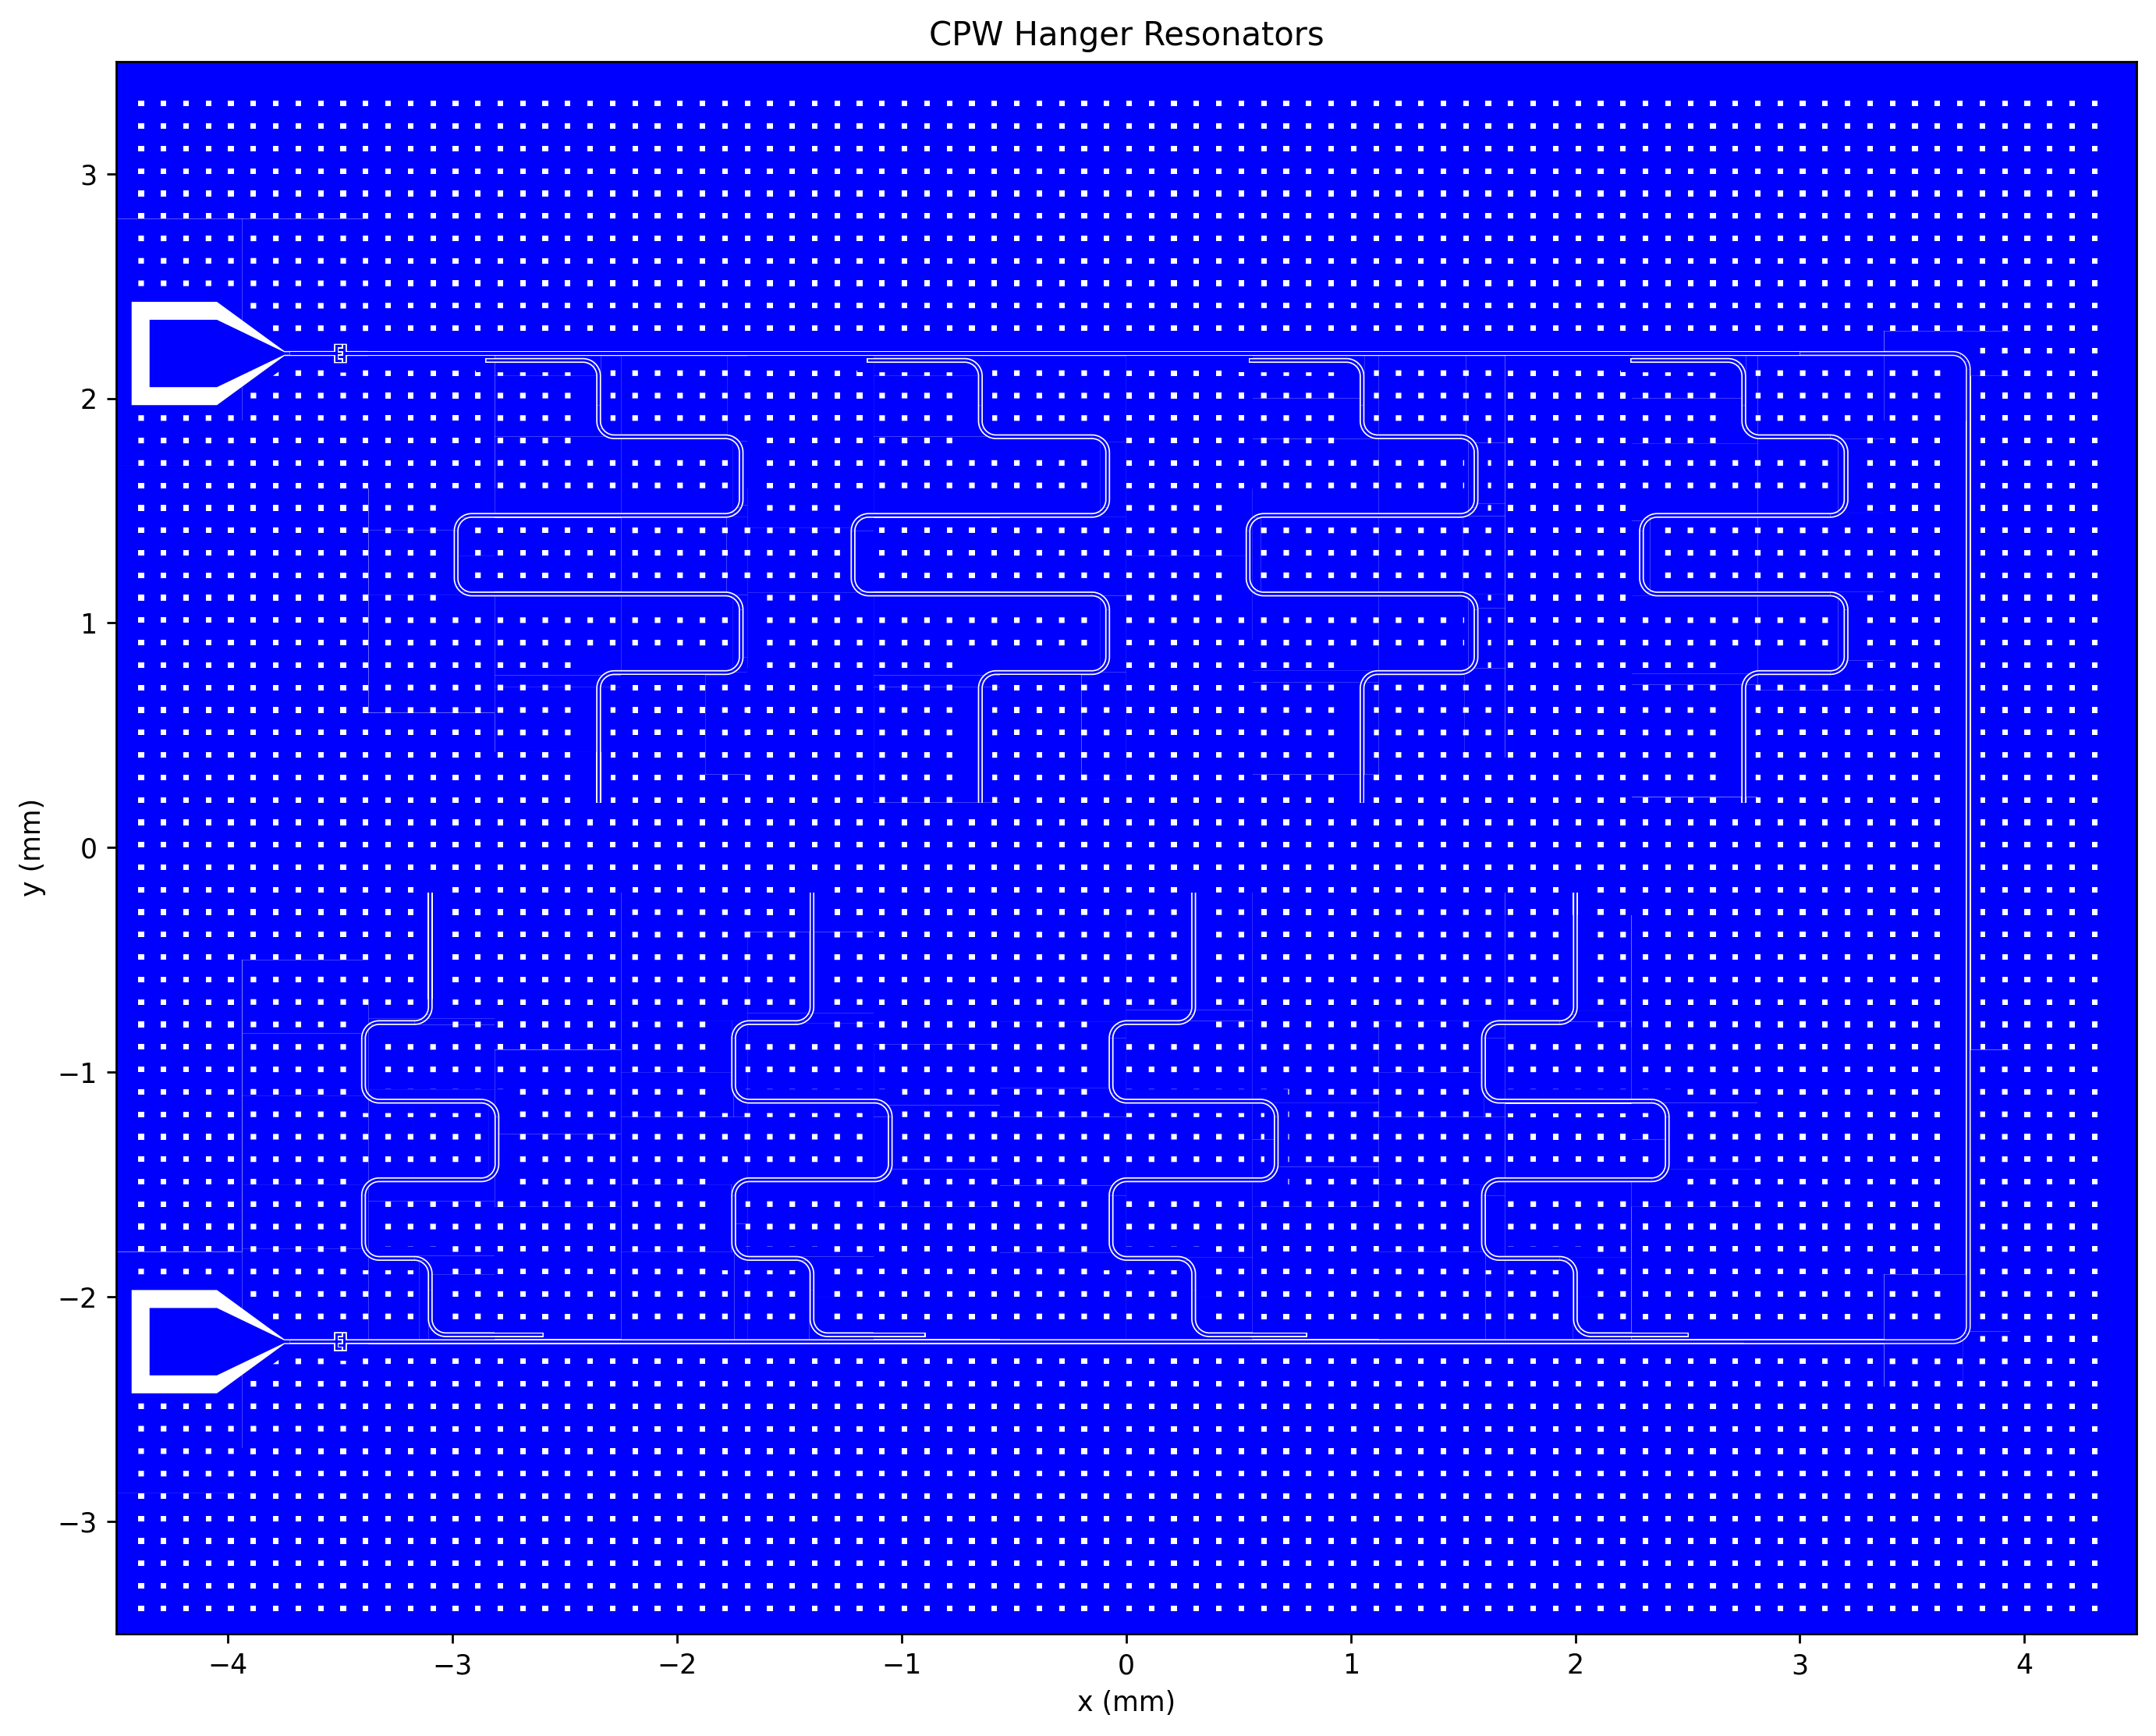

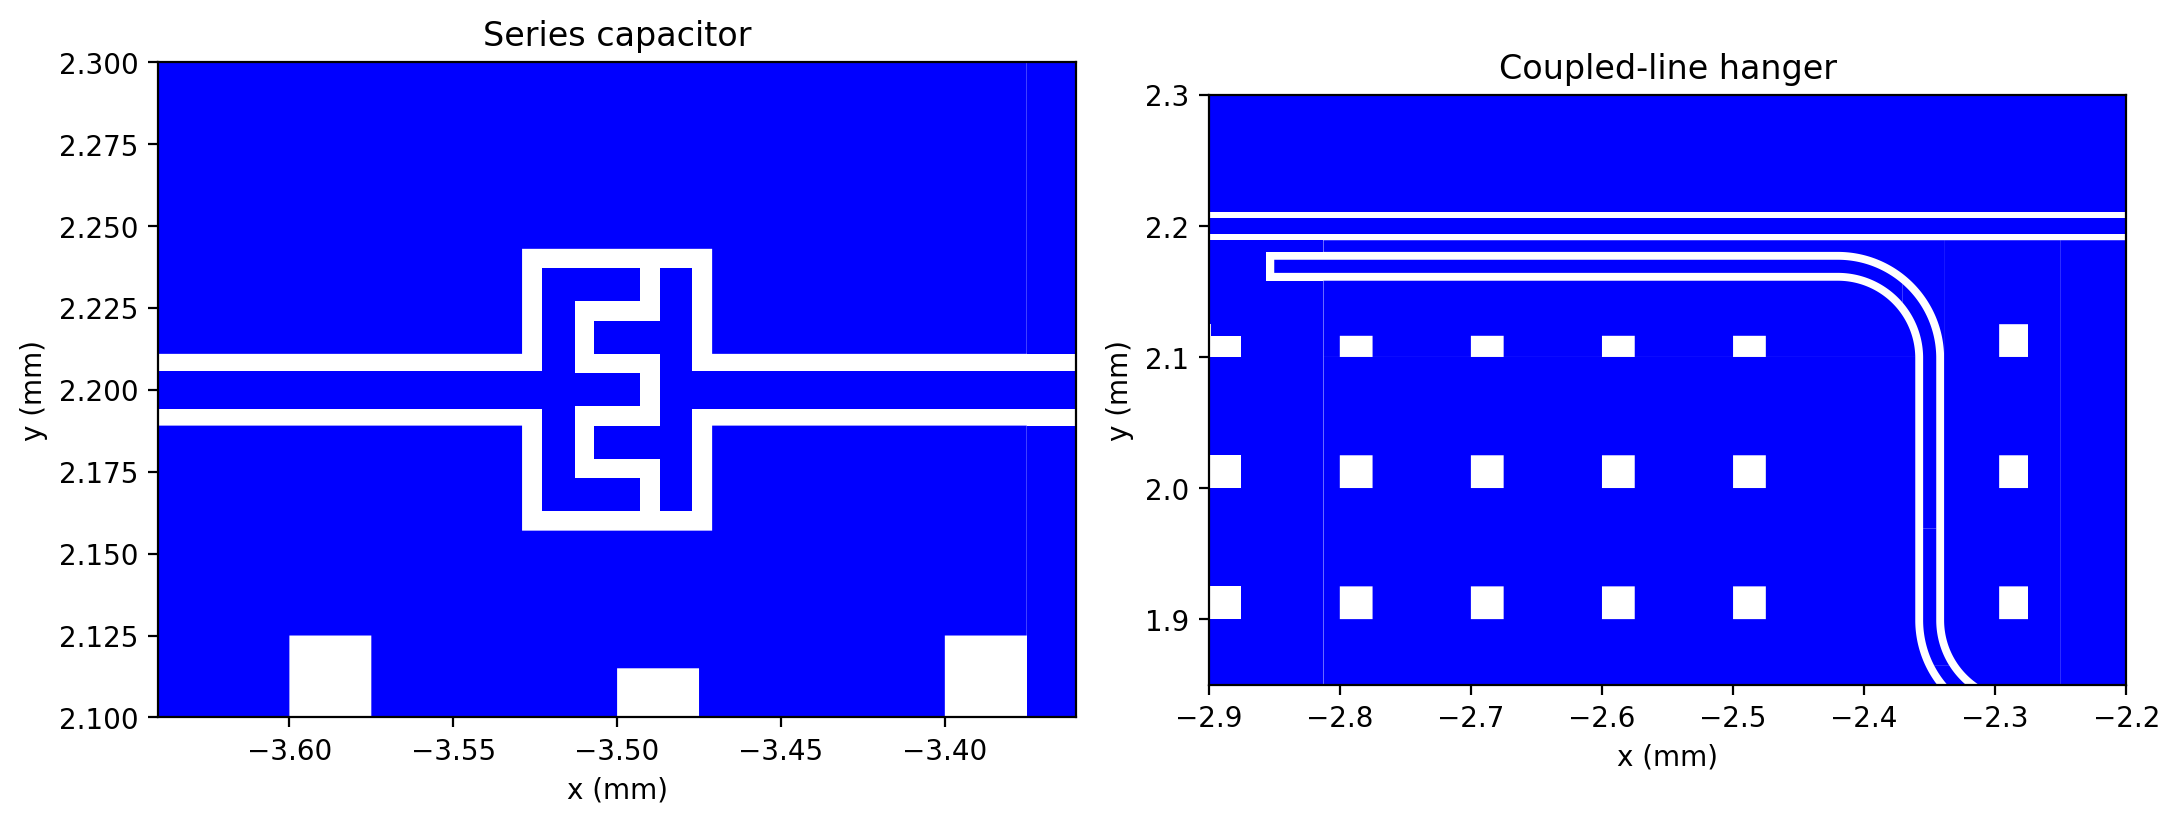

GDSII: Multi_CPW_Hanger_Resonators.gds (639,354 bytes)
Layer 1: positive ground, CPW circuit, and launcher electrodes


/content/Multi_CPW_Hanger_Resonators.gds

In [12]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""
gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds_renderer.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds_renderer.options.no_cheese.buffer = CHEESE_KEEPOUT

# Hole-center inset = 100 um clearance + half the native 25 um hole width.
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={1: True})
gds_renderer.options.no_cheese.view_in_file = Dict(main={1: False})

previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# Keep references only to cells present in the exported library.
cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {1}
assert np.isclose(verified_gds.precision, 1e-9)

# --- In-Memory Chip Preview ---
plt.rcParams['figure.dpi'] = 250
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'

fig, ax = plt.subplots(figsize=(12, 9))
ax.add_collection(PolyCollection(
    [polygon.points for polygon in exported_polygons],
    facecolor="#0000FF", edgecolor="none", rasterized=True,
))
ax.set_aspect("equal")
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_title("CPW Hanger Resonators")
for index, x, y in placements:
    ax.text(x, y, f"R{index}: {frequencies[index]:.4f} GHz",
            ha="center", fontsize=6, color="lightgrey", alpha=0.0)
fig.tight_layout()
plt.show()

# --- In-Memory Component Previews ---
detail_fig, detail_axes = plt.subplots(1, 2, figsize=(11, 4), dpi=200)
if INLINE_CAPACITORS:
    cap = end_caps[0]
    port_center = (cap.pins.north_end.middle + cap.pins.south_end.middle) / 2
else:
    port_center = launchpads[0].pins.tie.middle
port_x, port_y = port_center
tee = couplers[0]
views = (
    ((port_x - 0.140, port_x + 0.140), (port_y - 0.100, port_y + 0.100),
     "Series capacitor" if INLINE_CAPACITORS else "Direct feedline connection"),
    ((tee.p.pos_x - 0.300, tee.p.pos_x + 0.400),
     (tee.p.pos_y - 0.350, tee.p.pos_y + 0.100), "Coupled-line hanger"),
)
for ax, (xlimits, ylimits, title) in zip(detail_axes, views):
    ax.add_collection(PolyCollection(
        [polygon.points for polygon in exported_polygons],
        facecolor="#0000FF", edgecolor="none", rasterized=True,
    ))
    ax.set_aspect("equal")
    ax.set_xlim(*xlimits)
    ax.set_ylim(*ylimits)
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
detail_fig.tight_layout()
plt.show()
print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print("Layer 1: positive ground, CPW circuit, and launcher electrodes")
display(FileLink(str(out)))